# CX-101 Cellular Assay — Finalize Data processing pipeline 

Fictional experiment:
A concentration-response experiment investigating the effect of a fictional compound on intracellular calcium levels in cultured human muscle cells.
A newly identified compound is being investigated for its effect on intracellular calcium concentration in cultured human muscle cells.

The lab performs a concentration-response experiment.


* Compound: CX-101 (fictional)
* Cell type: cultured human skeletal muscle cells
* Concentrations: 0, 0.1, 1, 10, 100 nM, 1 µM
* Several biological/technical replicates
* Negative control: vehicle-treated cells
* Positive control: something known to induce a calcium response
* Measurement: intracellular calcium signal

Q: Does exposure to CX-101 produce a concentration-dependent change in intracellular calcium, and how reliable is the resulting dataset?


Pipeline:
Validation → cleaning → QC → statistical analysis → visualization → automated PDF report.

Input:
Messy Excel/CSV files containing experimental measurements, controls and replicates.

Output:
A reproducible analysis package plus a professional scientific report.


**For now, this notebook serves for development of the general framework for data cleaning and QC.**

## modules

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
%matplotlib inline

## Input

In [2]:
batch1 = pd.read_excel("../data/CX101_batch_1_raw.xlsx")
batch2 = pd.read_excel("../data/CX101_batch_2_raw.xlsx")
batch3 = pd.read_excel("../data/CX101_batch_3_raw.xlsx")

In [3]:
column_mapping = {
    "compound_name": "compound",
    "conc": "concentration",
    "concentration_unit": "unit",
    "replicate_id": "replicate",
    "response_rfu": "rfu",
    "batch_id": "batch",
    "well_position": "well",
    "plate": "plate_id",
    "rep": "replicate"
}

In [4]:
#construct mapping for compound
compound_mapping = {
    "cx101": "CX-101",
    "cx-101": "CX-101",
    "vehicle": "Vehicle",
    "ionomycin": "Ionomycin",
}



In [5]:
# in case we  neeed unit mapping
unit_mapping = {
    "nm": "nM",
    "NM": "nM",
    "µm": "µM",
    "uM": "µM",
}

eventually turn this into a standardization class 

In [6]:

def standardize_data(batch, column_mapping=column_mapping, compound_mapping=compound_mapping, unit_mapping=unit_mapping):

    def _log(change='column'):
        log = []
        if change == 'column':
            for old, new in column_mapping.items():
                if old in before.columns:
                    log.append([old, new])
            if log == []:
                log = ["standard schema - lowercase, whitespace removal"]
                
        else:            
            if change in before.columns:
                r_change = change
            else:
                r_change = r_column_mapping[change]
            changed = before[r_change] != df[change]
            if changed.any():                
                for i, b in enumerate(changed):
                    if b:
                        log.append([
                            i,
                            before[r_change][i], 
                            df[change][i]
                               ])

        return log

    log_d = {}
    
    # column names
    df = batch.copy()
    r_column_mapping = {v: k for k, v in column_mapping.items()}
    
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )
    before = df.copy() ## working solution for now... this is not entirely true
    df = df.rename(columns=column_mapping)
    
    # standardize compound names
    df["compound"] = df["compound"].str.strip()
    df["compound"] = df["compound"].str.lower()
    df["compound"] = df["compound"].replace(compound_mapping)
    
    # standardize units
    # print(df["unit"].unique())
    df["unit"] = df["unit"].str.strip()
    df["unit"] = df["unit"].replace(unit_mapping)

    # convert concentration to numeric
    df["concentration"] = pd.to_numeric(
        df["concentration"],
        errors="coerce"
    )

    # convert all concentrations to nM
    df.loc[df["unit"] == "µM", "concentration"] *= 1000

    # one canonical unit
    df["unit"] = "nM"
    
    log_d["batch"] = df.batch[0]
    log_d["column_renaming"] = _log()
    log_d["compound_standardization"] = _log(change="compound")
    log_d["unit_conversion(x1000)"] = _log(change="unit")
    
    
    return df, log_d

In [7]:
std_batch1, log1  = standardize_data(batch1)
std_batch2, log2  = standardize_data(batch2)
std_batch3, log3  = standardize_data(batch3)

In [8]:
log1, log2, log3

({'batch': 1,
  'column_renaming': ['standard schema - lowercase, whitespace removal'],
  'compound_standardization': [[8, 'CX101', 'CX-101']],
  'unit_conversion(x1000)': []},
 {'batch': 2,
  'column_renaming': [['conc', 'concentration'],
   ['concentration_unit', 'unit'],
   ['batch_id', 'batch'],
   ['well_position', 'well'],
   ['plate', 'plate_id'],
   ['rep', 'replicate']],
  'compound_standardization': [[12, 'cx-101', 'CX-101']],
  'unit_conversion(x1000)': [[18, 'µM', 'nM']]},
 {'batch': 3,
  'column_renaming': ['standard schema - lowercase, whitespace removal'],
  'compound_standardization': [[6, ' CX-101 ', 'CX-101']],
  'unit_conversion(x1000)': [[24, 'µM', 'nM']]})

In [9]:
df = pd.concat(
    [std_batch1, std_batch2,   std_batch3],
    ignore_index=True
)

## QC checks

In [10]:
required = [
    'batch', 'plate_id', 'well', "compound", "concentration", "unit", "replicate", "rfu"
]

missing_by_column = df[required].isna().sum()
missing_rows = df[df[required].isna().any(axis=1)]

# to be certain it's really a duplicated row and  not only a duplicate by chance, we focus on non-measured or non-calculated cols, to see all of them and detect true dup
duplicate_columns = [
    "batch", "compound", "concentration", "unit", "replicate", "rfu"
]

duplicates = df[
    df.duplicated(subset=duplicate_columns, keep=False)
]

# for cx-101, we could define:
allowed_concentrations = [
    0, 0.1, 1, 10, 100, 1000
]
invalid_concentrations = df[
    ~df["concentration"].isin(allowed_concentrations)
]

invalid_units = df[
    df["unit"].notna() & (df["unit"] != "nM")
]

missing_identifiers = df[
    df[["batch", "replicate"]].isna().any(axis=1)
]

print("Missing values by column:")
display(missing_by_column[missing_by_column > 0])

print("Duplicate rows:", len(duplicates))
print("Invalid concentrations:", len(invalid_concentrations))
print("Invalid units:", len(invalid_units))
print("Missing identifiers:", len(missing_identifiers))


Missing values by column:


replicate    1
rfu          1
dtype: int64

Duplicate rows: 2
Invalid concentrations: 0
Invalid units: 0
Missing identifiers: 1


**suspicious observations**

there seem to be outliers in the rfu value. lets see, if we can define some rules to identify truly suspicious values

In [14]:
# define the interquartile range to identify extreme values = potential  outliers
# for the basic pipeline this should be fine but sth to think about later:
# calc individual iqr for each condition an re-evaluate
def calc_iqr_outlier(column="rfu"):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    
    iqr = q3 - q1
    
    lower = q1 -  1.5 * iqr #outlier below iqr
    upper = q3 + 1.5 * iqr #outlier above iqr
    
    outlier = df[column][
        (df[column] < lower) |
        (df[column] > upper)
    ]
    return outlier

In [15]:
outlier

73    420.0
Name: rfu, dtype: float64

keep in mind :

An outlier could be:

* a measurement error
* biological variability
* a genuine response
* a pipetting problem
* an instrument issue|

## QC Summary

We record the problems identified by the pipeline. Use steps from standardization (log, not yet implemente) & QC checks to prepare a summary for QC assessment

In [16]:
prelim_qc_results = {}
prelim_qc_results["missing_values"] = df[["compound", "concentration", "unit", "rfu"]].isna().sum()


prelim_qc_results["duplicates"] = duplicates
# invalid_concentrations, compund name mismatch, and invalid_units are dealt with during standrardization process, 
# to make proper combination of the batches possible
# this will be recorded in standardization log and part of  the final QC summary
    
prelim_qc_results["missing_identifiers"] = df[
    df[["batch", "replicate"]].isna().any(axis=1)
]
prelim_qc_results["potential_rfu_outlier"] = outlier

In [17]:
checks = ["Missing RFU value", "Duplicate observation", "Missing replicate ID", "Potential RFU outliers"]
actions = ["Flag & exclude from response analysis", "Remove confirmed duplicate", "Flag", "Review"]
results = []
for check, result in prelim_qc_results.items():
    if isinstance(result, pd.DataFrame) or check == "potential_rfu_outlier": #hardcoded
        print(check,   result.__len__())
        results.append(result.__len__())
    else: #if isinstance(result, pd.Series):
        print(check, result.sum()) 
        results.append(result.sum())

missing_values 1
duplicates 2
missing_identifiers 1
potential_rfu_outlier 1


In [18]:
prelim_qc_summary = {
    "Check": checks,
    "Results": results,
    "Actions": actions
}


In [19]:
df_qc = pd.DataFrame.from_dict(prelim_qc_summary)

In [ ]:
df_qc

In [20]:
fn_qc_summary = "../reports/prelim_qc_summary.csv"
if os.path.exists(fn_qc_summary):
    print(f"{fn_qc_summary} exists")
else:
    df_qc.to_csv(fn_qc_summary)

../reports/prelim_qc_summary.csv exists


## Analysis

In [21]:
analysis_df = df.drop_duplicates(subset=duplicate_columns, keep="first").copy()

analysis_df = analysis_df.dropna(subset=["rfu"]).copy()

print("Raw rows:", len(df))
print("Analysis rows:", len(analysis_df))
print("Excluded rows:", len(df) - len(analysis_df))

Raw rows: 127
Analysis rows: 125
Excluded rows: 2


In [22]:
df[df.duplicated(subset=duplicate_columns)]

,experiment_date,batch,plate_id,well,compound,concentration,unit,replicate,rfu,notes
42,2026-08-11,1,P01,B11,CX-101,1.0,nM,5.0,145.27,NaN


In [23]:
df['rfu'][df['rfu'].isna()]

17   NaN
Name: rfu, dtype: float64

### descriptive statistics

In [24]:
summary = (analysis_df.groupby(["compound", "concentration"], dropna=False)["rfu"]
           .agg(n="count", mean="mean", std="std")
           .reset_index()
          )

# add standard error of the mean and coefficient of variation
summary["sem"] = summary["std"] / np.sqrt(summary["n"])
summary["cv_percent"] = summary["std"] / summary["mean"] * 100

display(summary)

,compound,concentration,n,mean,std,sem,cv_percent
0,CX-101,0.1,18,118.570556,18.970834,4.471468,15.999616
1,CX-101,1.0,18,133.872222,7.355910,1.733805,5.494725
2,CX-101,10.0,17,170.085882,8.623387,2.091479,5.070019
3,CX-101,100.0,18,228.546667,48.755716,11.491832,21.332937
4,CX-101,1000.0,20,229.604000,47.440063,10.607920,20.661688
5,Ionomycin,1000.0,16,247.356875,9.367071,2.341768,3.786865
6,Vehicle,0.0,18,99.401667,6.395089,1.507337,6.433584


### Visualise

First normalize to  vehicle -> account for background noise

For an exploratory visualization:

**response (% vehicle) = RFU / mean vehicle RFU × 100**



In [51]:
vehicle_mean = (summary.loc[summary["compound"] == "Vehicle", "mean"]).to_numpy()

In [52]:
vehicle_mean

array([99.40166667])

In [53]:
vehicle_mean = analysis_df.loc[
    analysis_df["compound"].eq("Vehicle"),
    "rfu"
].mean()

In [55]:
analysis_df["response_pct_vehicle"] = analysis_df["rfu"] / vehicle_mean * 100
normalized_summary = (analysis_df.groupby(["compound", "concentration"], dropna=False)["response_pct_vehicle"]
           .agg(n="count", mean="mean", std="std")
           .reset_index()

        )
normalized_summary["sem"] = normalized_summary["std"] / np.sqrt(normalized_summary["n"])
display(normalized_summary)

,compound,concentration,n,mean,std,sem
0,CX-101,0.1,18,119.284273,19.085026,4.498384
1,CX-101,1.0,18,134.678046,7.400188,1.744241
2,CX-101,10.0,17,171.109689,8.675294,2.104068
3,CX-101,100.0,18,229.922369,49.049193,11.561006
4,CX-101,1000.0,20,230.986067,47.725621,10.671773
5,Ionomycin,1000.0,16,248.845802,9.423455,2.355864
6,Vehicle,0.0,18,100.000000,6.433584,1.516410


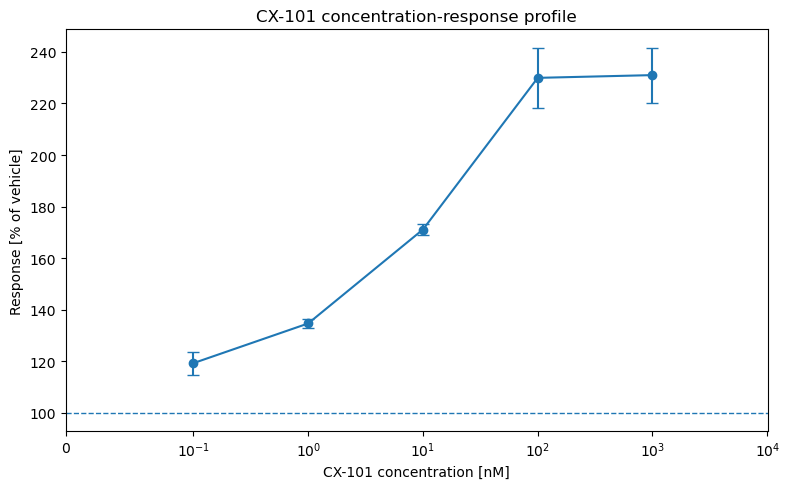

In [62]:
cx = normalized_summary[
    normalized_summary["compound"].eq("CX-101")
].sort_values("concentration")

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    cx["concentration"],
    cx["mean"],
    yerr=cx["sem"],
    marker="o",
    linestyle="-",
    capsize=4,
)
ax.axhline(100, linestyle="--", linewidth=1)
ax.set_xscale("symlog", linthresh=0.1)
ax.set(xlabel="CX-101 concentration [nM]", ylabel="Response [% of vehicle]", xlim=(0, 10100))
ax.set_title("CX-101 concentration-response profile")
plt.tight_layout()
# plt.show()
# fig_name = "cx-101_conc-respoxscale("symlog", linthresh=0.1))

### Batch-level consistency

In [67]:
batch_summary = (
    analysis_df
    .groupby(["batch", "compound", "concentration"])["rfu"]
    .agg(n="count", mean="mean", std="std")
    .reset_index()
)

batch_summary["cv_percent"] = (
    batch_summary["std"] / batch_summary["mean"] * 100
)


display(batch_summary)


,batch,compound,concentration,n,mean,std,cv_percent
0,1,CX-101,0.1,5,116.900000,6.511939,5.570521
1,1,CX-101,1.0,6,135.808333,6.509551,4.793190
2,1,CX-101,10.0,6,174.416667,3.873188,2.220653
3,1,CX-101,100.0,6,217.693333,10.307763,4.734993
4,1,CX-101,1000.0,7,239.604286,7.504503,3.132040
5,1,Ionomycin,1000.0,5,251.232000,7.324416,2.915399
6,1,Vehicle,0.0,6,97.316667,8.425705,8.658029
7,2,CX-101,0.1,6,110.523333,8.652435,7.828605
8,2,CX-101,1.0,6,129.246667,8.479332,6.560581
9,2,CX-101,10.0,6,162.225000,6.894295,4.249835


In [82]:
batch_summary[batch_summary['compound'] == 'CX-101'][batch_summary["concentration"] == 1000.0]

/var/folders/dh/r7h1rkd977v2zqb15q4h1dnr0000gp/T/ipykernel_68256/3788042309.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  batch_summary[batch_summary['compound'] == 'CX-101'][batch_summary["concentration"] == 1000.0]


,batch,compound,concentration,n,mean,std,cv_percent
4,1,CX-101,1000.0,7,239.604286,7.504503,3.132040
11,2,CX-101,1000.0,6,227.205000,4.665545,2.053452
18,3,CX-101,1000.0,7,221.660000,82.802544,37.355655


## Preliminary assessment

The pipeline can now distinguish:

- **standardization:** mechanical, traceable transformations
- **potential outliers:** observations requiring review rather than automatic deletion.
- **QC findings:** problems detected in the data
- **analysis exclusions:** observations that cannot contribute to the chosen analysis


In [71]:
assessment = []

if len(missing_rows):
    assessment.append(f"{len(missing_rows)} rows contain missing required values.")
if len(duplicates):
    assessment.append(f"{len(duplicates)} rows are involved in duplicate groups.")
if len(invalid_concentrations):
    assessment.append(f"{len(invalid_concentrations)} invalid concentrations were found.")
else:
    assessment.append("All non-missing concentrations match the expected concentration set.")
if len(invalid_units):
    assessment.append(f"{len(invalid_units)} non-canonical units remain.")
else:
    assessment.append("All non-missing concentration units are canonical nM.")
if len(missing_identifiers):
    assessment.append(f"{len(missing_identifiers)} rows have missing identifiers.")
if len(outlier):
    assessment.append(f"{len(outlier)} potential RFU outlier was flagged by the IQR rule.")
else:
    assessment.append("No potential RFU outliers were flagged by the IQR rule.")

for message in assessment:
    print("•", message)


• 2 rows contain missing required values.
• 2 rows are involved in duplicate groups.
• All non-missing concentrations match the expected concentration set.
• All non-missing concentration units are canonical nM.
• 1 rows have missing identifiers.
• 1 potential RFU outlier was flagged by the IQR rule.


TODO

- prep standardization log and include in QC summary
- fine tune analysis
    - condition specific QC filters
    - appropriate inferential statistics
    - better batch-effect assessment
- automated (PDF) report generation